# 07. Huấn luyện và so sánh nhiều mô hình (thư viện)
| Nhóm | Mô hình |
|---|---|
| Tuyến tính | Linear Regression, Ridge (chọn α bằng CV), Lasso, ElasticNet |
| Lân cận | K-Nearest Neighbors |
| Cây đơn | Decision Tree (khảo sát độ sâu – quá khớp) |
| Bagging | Random Forest, Extra Trees |
| Boosting | HistGradientBoosting, XGBoost, LightGBM (dò tham số ngẫu nhiên), CatBoost |
| Mạng nơ-ron | MLP 3 lớp ẩn |
| Kết hợp | Trung bình 3 mô hình boosting; trọng số tối ưu (NNLS) học trên validation |

Tất cả dùng chung dữ liệu đặc trưng của notebook 05. Siêu tham số chọn trên tập validation (hoặc dừng sớm theo validation), kết quả cuối báo cáo trên tập test. Cuối notebook kiểm định chéo 5-fold để xem độ ổn định của các mô hình tốt nhất.

In [1]:
import sys, os, time, json, warnings
sys.path.append('../src')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostRegressor
from scipy.optimize import nnls
from sklearn.linear_model import LinearRegression, RidgeCV, Lasso, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import KFold
from danh_gia import chi_so

warnings.filterwarnings('ignore')
pd.set_option('display.width', 170)
sns.set_theme(style='whitegrid')
FIG = '../reports/figures'
doc = lambda t: pd.read_parquet(f'../data/processed/dac_trung_{t}.parquet')
tr, va, te = doc('train'), doc('val'), doc('test')
COT_X = [c for c in tr.columns if c not in ('y', 'trong_so') and not c.startswith('_')]
X_tr, y_tr = tr[COT_X].values, tr['y'].values.astype(np.float64)
X_va, y_va = va[COT_X].values, va['y'].values.astype(np.float64)
X_te, y_te = te[COT_X].values, te['y'].values.astype(np.float64)
print('Số đặc trưng:', len(COT_X), '| train', X_tr.shape, '| val', X_va.shape, '| test', X_te.shape)

ket_qua, du_doan_val, du_doan_test = {}, {}, {}
def ghi(ten, nhom, mh, t_fit, f=lambda X: X):
    du_doan_val[ten] = mh.predict(f(X_va)).astype(np.float64)
    du_doan_test[ten] = mh.predict(f(X_te)).astype(np.float64)
    ket_qua[ten] = {'Nhóm': nhom, 'val RMSE log': chi_so(y_va, du_doan_val[ten])['RMSE log'],
                    **chi_so(y_te, du_doan_test[ten]), 'Thời gian huấn luyện (s)': round(t_fit, 1)}
    print(f"{ten:42s} val RMSE {ket_qua[ten]['val RMSE log']:.4f} | test RMSE {ket_qua[ten]['RMSE log']:.4f} | "
          f"R² {ket_qua[ten]['R² log']:.4f} | lệch ≤20%: {ket_qua[ten]['Lệch ≤20% (%)']:.1f}% | {t_fit:.0f}s")

Số đặc trưng: 44 | train (604466, 44) | val (129529, 44) | test (129529, 44)


## 1. Nhóm mô hình tuyến tính
Dùng float64 (float32 làm sklearn mất độ chính xác khi giải bình phương tối thiểu – xem notebook 06).

In [2]:
f64 = lambda X: X.astype(np.float64)
X64 = f64(X_tr)
for ten, mh in [('Linear Regression', LinearRegression()),
                ('Ridge (α chọn bằng CV)', RidgeCV(alphas=[0.01, 0.1, 1, 10, 100, 1000])),
                ('Lasso (α = 0,0005)', Lasso(alpha=0.0005, max_iter=3000)),
                ('ElasticNet (α = 0,001, l1 = 0,5)', ElasticNet(alpha=0.001, l1_ratio=0.5, max_iter=3000))]:
    t = time.time(); mh.fit(X64, y_tr)
    ghi(ten, 'Tuyến tính', mh, time.time() - t, f64)
del X64

Linear Regression                          val RMSE 0.4954 | test RMSE 0.4931 | R² 0.7946 | lệch ≤20%: 40.6% | 1s


Ridge (α chọn bằng CV)                     val RMSE 0.4954 | test RMSE 0.4931 | R² 0.7946 | lệch ≤20%: 40.6% | 3s


Lasso (α = 0,0005)                         val RMSE 0.4954 | test RMSE 0.4932 | R² 0.7945 | lệch ≤20%: 40.6% | 17s


ElasticNet (α = 0,001, l1 = 0,5)           val RMSE 0.4955 | test RMSE 0.4933 | R² 0.7945 | lệch ≤20%: 40.6% | 17s


## 2. K-Nearest Neighbors
KNN phải tính khoảng cách tới mọi mẫu huấn luyện khi dự đoán, nên dùng mẫu con 200.000 dòng. Chọn k trên 20.000 mẫu validation.

In [3]:
rng = np.random.default_rng(42)
i_knn = rng.choice(len(X_tr), 200000, replace=False)
j_knn = rng.choice(len(X_va), 20000, replace=False)
chon_k = {}
for k in [5, 10, 20, 40]:
    mh = KNeighborsRegressor(n_neighbors=k, weights='distance', algorithm='brute', n_jobs=-1).fit(X_tr[i_knn], y_tr[i_knn])
    chon_k[k] = chi_so(y_va[j_knn], mh.predict(X_va[j_knn]))['RMSE log']
K_TOT = min(chon_k, key=chon_k.get)
print('RMSE val theo k:', {k: round(v, 4) for k, v in chon_k.items()}, '-> chọn k =', K_TOT)
t = time.time(); knn = KNeighborsRegressor(n_neighbors=K_TOT, weights='distance', algorithm='brute', n_jobs=-1).fit(X_tr[i_knn], y_tr[i_knn])
ghi(f'KNN (k = {K_TOT}, 200.000 mẫu)', 'Lân cận', knn, time.time() - t)
del knn

RMSE val theo k: {5: 0.5044, 10: 0.4974, 20: 0.5048, 40: 0.52} -> chọn k = 10


KNN (k = 10, 200.000 mẫu)                  val RMSE 0.4994 | test RMSE 0.4968 | R² 0.7915 | lệch ≤20%: 44.2% | 0s


## 3. Decision Tree – độ sâu và hiện tượng quá khớp

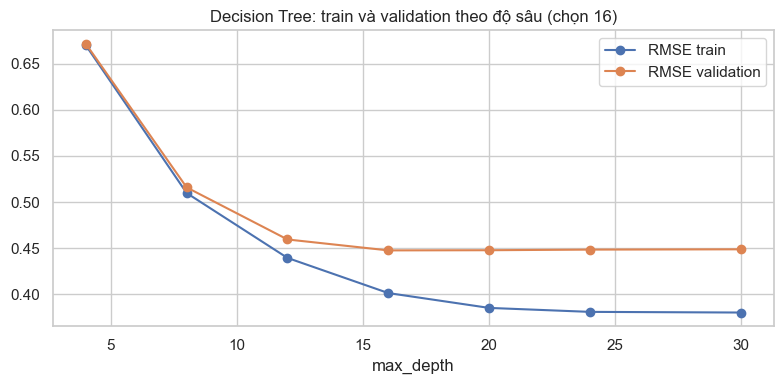

Decision Tree (độ sâu 16)                  val RMSE 0.4477 | test RMSE 0.4464 | R² 0.8317 | lệch ≤20%: 48.4% | 8s


,4,8,12,16,20,24,30
RMSE train,0.6699,0.5098,0.4396,0.4015,0.3854,0.3811,0.3804
RMSE validation,0.6715,0.5159,0.4595,0.4477,0.4479,0.4486,0.4489


In [4]:
sau = {}
for d in [4, 8, 12, 16, 20, 24, 30]:
    mh = DecisionTreeRegressor(max_depth=d, min_samples_leaf=20, random_state=42).fit(X_tr, y_tr)
    sau[d] = {'RMSE train': chi_so(y_tr, mh.predict(X_tr))['RMSE log'], 'RMSE validation': chi_so(y_va, mh.predict(X_va))['RMSE log']}
sau = pd.DataFrame(sau).T
D_TOT = int(sau['RMSE validation'].idxmin())
ax = sau.plot(marker='o', figsize=(8, 4)); ax.set_xlabel('max_depth'); ax.set_title(f'Decision Tree: train và validation theo độ sâu (chọn {D_TOT})')
plt.tight_layout(); plt.savefig(f'{FIG}/07_cay_quyet_dinh.png', dpi=120); plt.show()
t = time.time(); cay = DecisionTreeRegressor(max_depth=D_TOT, min_samples_leaf=20, random_state=42).fit(X_tr, y_tr)
ghi(f'Decision Tree (độ sâu {D_TOT})', 'Cây đơn', cay, time.time() - t)
sau.round(4).T

## 4. Bagging: Random Forest và Extra Trees
Mỗi cây học trên 25% dữ liệu bốc ngẫu nhiên có hoàn lại, mỗi lần tách xét 50% đặc trưng.

In [5]:
for ten, mh in [('Random Forest (100 cây)', RandomForestRegressor(n_estimators=100, max_features=0.5, min_samples_leaf=5, max_samples=0.25, n_jobs=-1, random_state=42)),
                ('Extra Trees (100 cây)', ExtraTreesRegressor(n_estimators=100, max_features=0.5, min_samples_leaf=5, bootstrap=True, max_samples=0.25, n_jobs=-1, random_state=42))]:
    t = time.time(); mh.fit(X_tr, y_tr)
    ghi(ten, 'Bagging', mh, time.time() - t)
    del mh

Random Forest (100 cây)                    val RMSE 0.4089 | test RMSE 0.4066 | R² 0.8603 | lệch ≤20%: 53.2% | 24s


Extra Trees (100 cây)                      val RMSE 0.4187 | test RMSE 0.4162 | R² 0.8537 | lệch ≤20%: 50.9% | 23s


## 5. Boosting
### 5a. HistGradientBoosting (scikit-learn) và XGBoost

In [6]:
t = time.time()
hgb = HistGradientBoostingRegressor(max_iter=3000, learning_rate=0.08, max_leaf_nodes=255, min_samples_leaf=40, l2_regularization=1.0,
                                    early_stopping=True, validation_fraction=0.1, n_iter_no_change=50, random_state=42).fit(X_tr, y_tr)
ghi(f'HistGradientBoosting ({hgb.n_iter_} vòng)', 'Boosting', hgb, time.time() - t)
del hgb
THAM_SO_XGB = dict(tree_method='hist', learning_rate=0.05, max_depth=9, min_child_weight=5, subsample=0.8, colsample_bytree=0.8,
                   reg_lambda=1.0, n_jobs=-1, random_state=42, eval_metric='rmse')
t = time.time()
mh_xgb = xgb.XGBRegressor(n_estimators=5000, early_stopping_rounds=150, **THAM_SO_XGB).fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
ghi(f'XGBoost ({mh_xgb.best_iteration + 1} cây)', 'Boosting', mh_xgb, time.time() - t)

HistGradientBoosting (1770 vòng)           val RMSE 0.3889 | test RMSE 0.3848 | R² 0.8749 | lệch ≤20%: 55.7% | 126s


XGBoost (3867 cây)                         val RMSE 0.3866 | test RMSE 0.3835 | R² 0.8758 | lệch ≤20%: 56.0% | 188s


### 5b. LightGBM – dò tham số ngẫu nhiên
12 cấu hình ngẫu nhiên (số lá, số mẫu tối thiểu mỗi lá, tỉ lệ lấy mẫu dòng/cột, phạt L2), tốc độ học 0,1 và dừng sớm theo validation để so sánh nhanh; cấu hình tốt nhất được huấn luyện lại với tốc độ học 0,03.

In [7]:
rng = np.random.default_rng(7)
thu = []
for i in range(12):
    ts = dict(num_leaves=int(rng.choice([63, 127, 255, 511, 1023])), min_child_samples=int(rng.choice([10, 20, 50, 100])),
              subsample=float(rng.choice([0.6, 0.8, 1.0])), colsample_bytree=float(rng.choice([0.5, 0.7, 0.9])),
              reg_lambda=float(rng.choice([0.0, 1.0, 5.0, 20.0])))
    t = time.time()
    mh = lgb.LGBMRegressor(n_estimators=4000, learning_rate=0.1, subsample_freq=1, n_jobs=-1, random_state=42, verbose=-1, **ts)
    mh.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], callbacks=[lgb.early_stopping(100, verbose=False)])
    thu.append({**ts, 'số cây': mh.best_iteration_, 'RMSE val': chi_so(y_va, mh.predict(X_va))['RMSE log'], 'thời gian (s)': round(time.time() - t)})
thu = pd.DataFrame(thu).sort_values('RMSE val')
TS_LGB = {k: (int(v) if k in ('num_leaves', 'min_child_samples') else float(v)) for k, v in thu.iloc[0][['num_leaves', 'min_child_samples', 'subsample', 'colsample_bytree', 'reg_lambda']].items()}
print('Cấu hình tốt nhất:', TS_LGB)
thu.round(4)

Cấu hình tốt nhất: {'num_leaves': 1023, 'min_child_samples': 10, 'subsample': 1.0, 'colsample_bytree': 0.5, 'reg_lambda': 1.0}


,num_leaves,min_child_samples,subsample,colsample_bytree,reg_lambda,số cây,RMSE val,thời gian (s)
3,1023,10,1.0,0.5,1.0,1015,0.3860,95
8,255,10,1.0,0.5,20.0,1771,0.3863,68
0,1023,50,1.0,0.9,5.0,566,0.3867,71
2,127,100,1.0,0.5,1.0,3324,0.3876,113
10,63,50,1.0,0.7,20.0,4000,0.3880,80
4,1023,20,0.8,0.5,5.0,581,0.3881,73
7,511,50,0.8,0.7,20.0,907,0.3891,72
6,255,50,0.8,0.9,20.0,1739,0.3893,72
11,1023,100,0.8,0.7,5.0,387,0.3893,68
5,127,100,0.8,0.7,5.0,2591,0.3907,79


In [8]:
t = time.time()
mh_lgb = lgb.LGBMRegressor(n_estimators=20000, learning_rate=0.03, subsample_freq=1, n_jobs=-1, random_state=42, verbose=-1, **TS_LGB)
mh_lgb.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], callbacks=[lgb.early_stopping(300, verbose=False)])
ghi(f'LightGBM ({mh_lgb.best_iteration_} cây, đã dò tham số)', 'Boosting', mh_lgb, time.time() - t)

LightGBM (3684 cây, đã dò tham số)         val RMSE 0.3806 | test RMSE 0.3770 | R² 0.8800 | lệch ≤20%: 57.2% | 310s


### 5c. CatBoost

In [9]:
t = time.time()
mh_cat = CatBoostRegressor(iterations=6000, learning_rate=0.08, depth=8, l2_leaf_reg=3, loss_function='RMSE', thread_count=-1,
                           random_seed=42, od_type='Iter', od_wait=200, verbose=0)
mh_cat.fit(X_tr, y_tr, eval_set=(X_va, y_va), use_best_model=True)
ghi(f'CatBoost ({mh_cat.get_best_iteration() + 1} cây)', 'Boosting', mh_cat, time.time() - t)

CatBoost (6000 cây)                        val RMSE 0.3898 | test RMSE 0.3864 | R² 0.8739 | lệch ≤20%: 54.7% | 341s


## 6. Mạng nơ-ron MLP
3 lớp ẩn 256–128–64, ReLU, tối ưu Adam, lô 2.048 mẫu, dừng sớm khi điểm trên 10% dữ liệu tách riêng không cải thiện sau 5 vòng.

MLP 256-128-64 (44 vòng)                   val RMSE 0.4369 | test RMSE 0.4340 | R² 0.8410 | lệch ≤20%: 47.3% | 272s


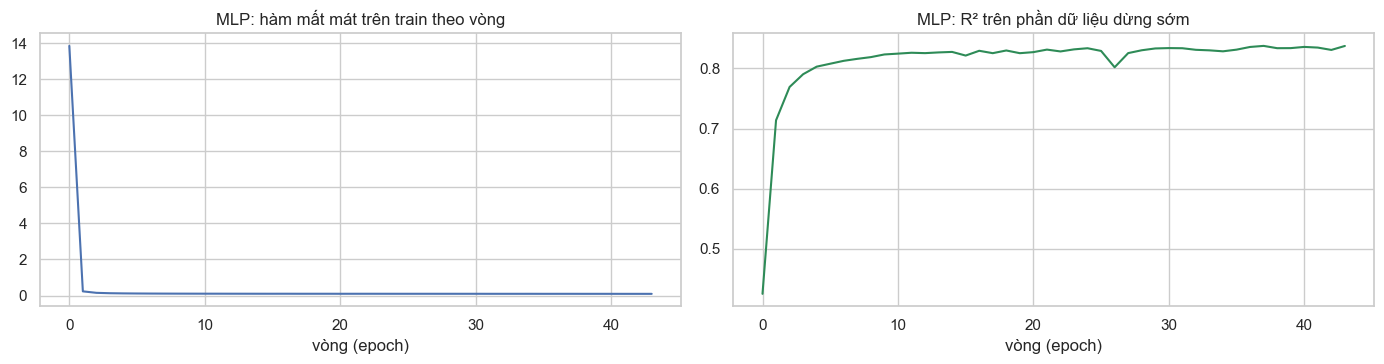

In [10]:
t = time.time()
mlp = MLPRegressor(hidden_layer_sizes=(256, 128, 64), activation='relu', solver='adam', batch_size=2048, learning_rate_init=1e-3,
                   alpha=1e-4, max_iter=60, early_stopping=True, validation_fraction=0.1, n_iter_no_change=5, random_state=42)
mlp.fit(X_tr, y_tr)
ghi(f'MLP 256-128-64 ({mlp.n_iter_} vòng)', 'Mạng nơ-ron', mlp, time.time() - t)
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
ax[0].plot(mlp.loss_curve_); ax[0].set_title('MLP: hàm mất mát trên train theo vòng'); ax[0].set_xlabel('vòng (epoch)')
ax[1].plot(mlp.validation_scores_, color='seagreen'); ax[1].set_title('MLP: R² trên phần dữ liệu dừng sớm'); ax[1].set_xlabel('vòng (epoch)')
plt.tight_layout(); plt.savefig(f'{FIG}/07_mlp.png', dpi=120); plt.show()
del mlp

## 7. Kết hợp mô hình (ensemble)
- Trung bình cộng dự đoán của XGBoost, LightGBM, CatBoost
- Trọng số tối ưu: tìm trọng số không âm (NNLS) sao cho tổ hợp dự đoán khớp nhất với **tập validation**, rồi đánh giá trên test

In [11]:
THANH_PHAN = [k for k in ket_qua if k.startswith(('XGBoost', 'LightGBM', 'CatBoost'))]
P_va = np.column_stack([du_doan_val[k] for k in THANH_PHAN])
P_te = np.column_stack([du_doan_test[k] for k in THANH_PHAN])
class TrungBinh:
    def __init__(self, w): self.w = np.asarray(w) / np.sum(w)
    def predict(self, P): return P @ self.w
w_nnls, _ = nnls(P_va, y_va)
print('Trọng số NNLS:', dict(zip(THANH_PHAN, np.round(w_nnls / w_nnls.sum(), 3))))
for ten, w in [('Ensemble: trung bình 3 boosting', np.ones(len(THANH_PHAN))), ('Ensemble: trọng số tối ưu (NNLS)', w_nnls)]:
    mh = TrungBinh(w)
    du_doan_val[ten], du_doan_test[ten] = mh.predict(P_va), mh.predict(P_te)
    ket_qua[ten] = {'Nhóm': 'Kết hợp', 'val RMSE log': chi_so(y_va, du_doan_val[ten])['RMSE log'], **chi_so(y_te, du_doan_test[ten]),
                    'Thời gian huấn luyện (s)': sum(ket_qua[k]['Thời gian huấn luyện (s)'] for k in THANH_PHAN)}
    print(ten, round(ket_qua[ten]['RMSE log'], 4))
TRONG_SO_ENSEMBLE = dict(zip(THANH_PHAN, (w_nnls / w_nnls.sum()).tolist()))

Trọng số NNLS: {'XGBoost (3867 cây)': np.float64(0.195), 'LightGBM (3684 cây, đã dò tham số)': np.float64(0.663), 'CatBoost (6000 cây)': np.float64(0.142)}
Ensemble: trung bình 3 boosting 0.3772
Ensemble: trọng số tối ưu (NNLS) 0.3758


## 8. Bảng so sánh tất cả mô hình (gồm cả 4 mô hình tự code ở notebook 06)

In [12]:
bang = pd.DataFrame(ket_qua).T
tu_code = pd.read_csv('../reports/ket_qua_tu_code.csv', index_col=0)
tu_code = tu_code.drop(index=[i for i in tu_code.index if i.startswith('Mốc')])
tu_code['Nhóm'] = 'Tự code (NumPy)'
tu_code['val RMSE log'] = tu_code['val RMSE log']
tat_ca = pd.concat([bang, tu_code[bang.columns]]).sort_values('RMSE log')
tat_ca.to_csv('../reports/so_sanh_tat_ca_mo_hinh.csv', encoding='utf-8-sig')
COT_HIEN = ['Nhóm', 'val RMSE log', 'RMSE log', 'R² log', 'MAE (tỷ)', 'MAPE (%)', 'Trung vị APE (%)', 'Lệch ≤10% (%)', 'Lệch ≤20% (%)', 'Thời gian huấn luyện (s)']
tat_ca[COT_HIEN].style.format({c: '{:.4f}' for c in COT_HIEN[1:4]} | {c: '{:.2f}' for c in COT_HIEN[4:]}).background_gradient(subset=['RMSE log'], cmap='RdYlGn_r')

,Nhóm,val RMSE log,RMSE log,R² log,MAE (tỷ),MAPE (%),Trung vị APE (%),Lệch ≤10% (%),Lệch ≤20% (%),Thời gian huấn luyện (s)
Ensemble: trọng số tối ưu (NNLS),Kết hợp,0.3793,0.3758,0.8807,3.87,27.79,16.55,33.47,57.17,839.00
"LightGBM (3684 cây, đã dò tham số)",Boosting,0.3806,0.3770,0.8800,3.87,27.80,16.45,33.61,57.18,310.50
Ensemble: trung bình 3 boosting,Kết hợp,0.3806,0.3772,0.8799,3.90,28.02,16.78,32.89,56.63,839.00
XGBoost (3867 cây),Boosting,0.3866,0.3835,0.8758,3.97,28.70,17.07,32.35,55.96,188.00
HistGradientBoosting (1770 vòng),Boosting,0.3889,0.3848,0.8749,3.98,28.64,17.18,32.23,55.71,125.90
CatBoost (6000 cây),Boosting,0.3898,0.3864,0.8739,4.04,29.05,17.65,31.21,54.73,340.50
Random Forest (100 cây),Bagging,0.4089,0.4066,0.8603,4.30,30.61,18.36,30.51,53.18,23.90
Extra Trees (100 cây),Bagging,0.4187,0.4162,0.8537,4.55,31.57,19.53,28.49,50.92,23.20
MLP 256-128-64 (44 vòng),Mạng nơ-ron,0.4369,0.4340,0.8410,4.66,35.03,21.45,25.84,47.28,272.30
Decision Tree (độ sâu 16),Cây đơn,0.4477,0.4464,0.8317,4.68,34.76,20.86,26.88,48.41,7.70


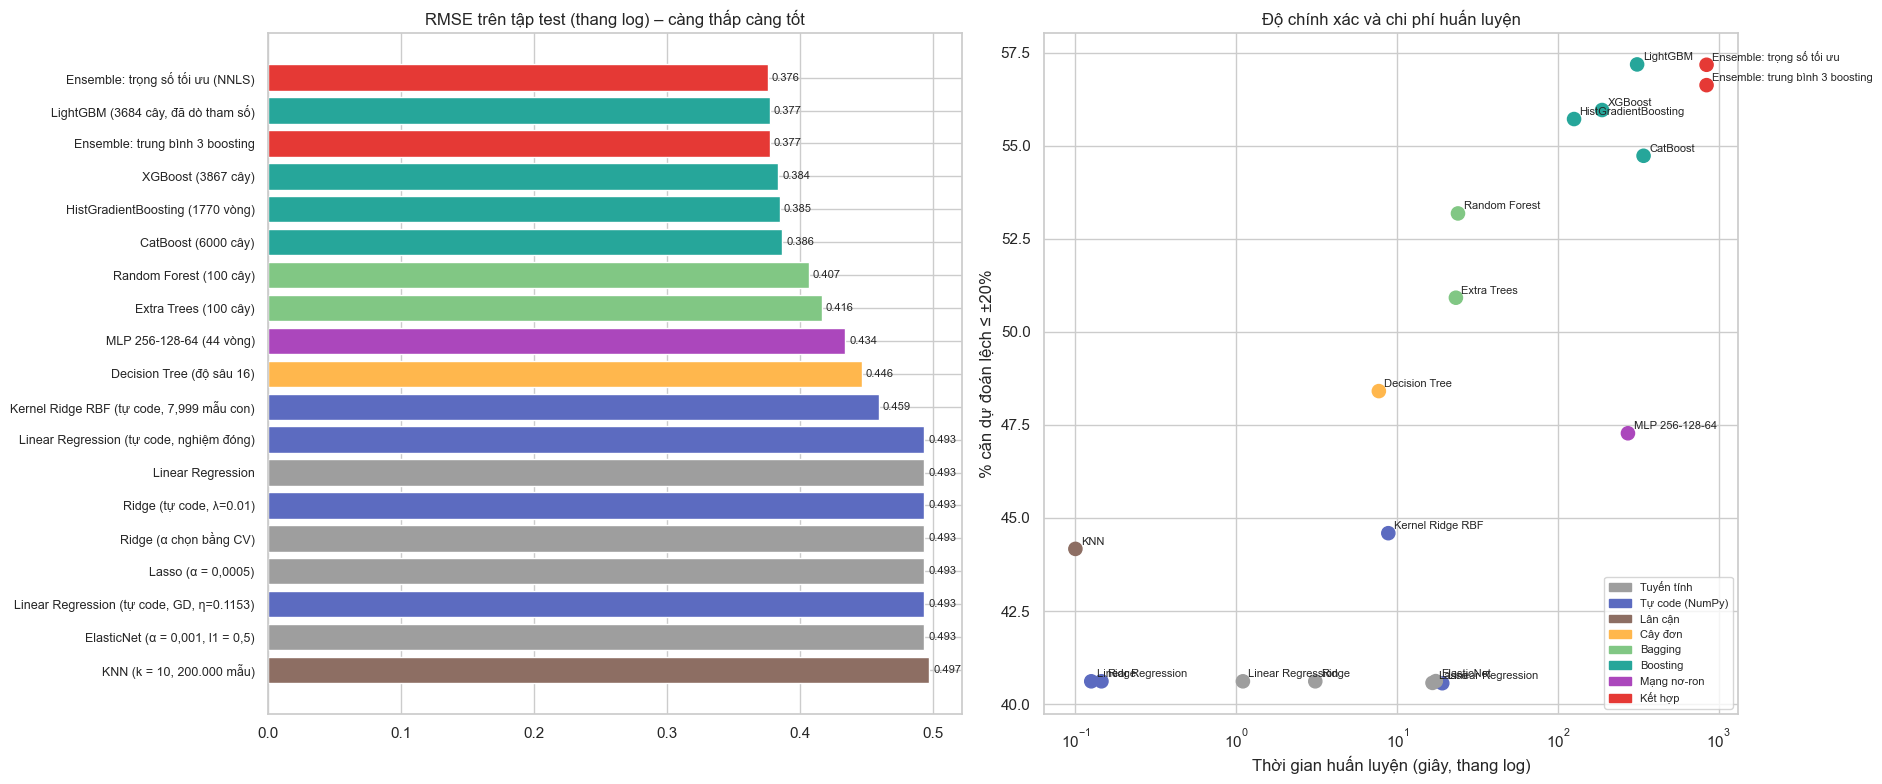

In [13]:
mau_nhom = {'Tuyến tính': '#9e9e9e', 'Tự code (NumPy)': '#5c6bc0', 'Lân cận': '#8d6e63', 'Cây đơn': '#ffb74d', 'Bagging': '#81c784',
            'Boosting': '#26a69a', 'Mạng nơ-ron': '#ab47bc', 'Kết hợp': '#e53935'}
fig, ax = plt.subplots(1, 2, figsize=(19, 8))
d = tat_ca.sort_values('RMSE log', ascending=False)
ax[0].barh(d.index, d['RMSE log'], color=[mau_nhom[n] for n in d['Nhóm']])
ax[0].set_title('RMSE trên tập test (thang log) – càng thấp càng tốt'); ax[0].tick_params(axis='y', labelsize=9)
for i, v in enumerate(d['RMSE log']):
    ax[0].text(v + 0.003, i, f'{v:.3f}', va='center', fontsize=8)
ax[1].scatter(tat_ca['Thời gian huấn luyện (s)'].astype(float).clip(lower=0.1), tat_ca['Lệch ≤20% (%)'], s=90,
              c=[mau_nhom[n] for n in tat_ca['Nhóm']])
for ten, h in tat_ca.iterrows():
    ax[1].annotate(ten.split(' (')[0], (max(float(h['Thời gian huấn luyện (s)']), 0.1), h['Lệch ≤20% (%)']), fontsize=8, xytext=(4, 3), textcoords='offset points')
ax[1].set_xscale('log'); ax[1].set_xlabel('Thời gian huấn luyện (giây, thang log)'); ax[1].set_ylabel('% căn dự đoán lệch ≤ ±20%')
ax[1].set_title('Độ chính xác và chi phí huấn luyện')
from matplotlib.patches import Patch
ax[1].legend(handles=[Patch(color=v, label=k) for k, v in mau_nhom.items()], fontsize=8, loc='lower right')
plt.tight_layout(); plt.savefig(f'{FIG}/07_so_sanh_tat_ca.png', dpi=120); plt.show()

## 9. Kiểm định chéo 5-fold (độ ổn định)
Trên mẫu con 200.000 dòng của tập train, cùng cấu hình, số cây cố định theo kết quả dừng sớm ở trên (tốc độ học 0,1 để chạy nhanh).

In [14]:
i_cv = np.random.default_rng(3).choice(len(X_tr), 200000, replace=False)
Xc, yc = X_tr[i_cv], y_tr[i_cv]
kf = KFold(5, shuffle=True, random_state=42)
mau_cv = {
    'LightGBM': lambda: lgb.LGBMRegressor(n_estimators=1500, learning_rate=0.1, subsample_freq=1, n_jobs=-1, random_state=42, verbose=-1, **TS_LGB),
    'XGBoost': lambda: xgb.XGBRegressor(n_estimators=1000, **{**THAM_SO_XGB, 'learning_rate': 0.1}),
    'CatBoost': lambda: CatBoostRegressor(iterations=2000, learning_rate=0.15, depth=8, thread_count=-1, random_seed=42, verbose=0),
    'Random Forest': lambda: RandomForestRegressor(n_estimators=60, max_features=0.5, min_samples_leaf=5, max_samples=0.5, n_jobs=-1, random_state=42),
}
cv = {}
for ten, tao_mh in mau_cv.items():
    diem = []
    for a, b in kf.split(Xc):
        mh = tao_mh().fit(Xc[a], yc[a])
        diem.append(chi_so(yc[b], mh.predict(Xc[b]))['RMSE log'])
    cv[ten] = {'RMSE trung bình 5 fold': np.mean(diem), 'Độ lệch chuẩn': np.std(diem), 'Nhỏ nhất': np.min(diem), 'Lớn nhất': np.max(diem)}
    print(ten, [round(x, 4) for x in diem])
pd.DataFrame(cv).T.round(4)

LightGBM [0.4184, 0.4184, 0.4135, 0.4137, 0.4164]


XGBoost [0.4118, 0.4132, 0.4087, 0.4073, 0.4124]


CatBoost [0.4094, 0.4089, 0.4058, 0.4036, 0.4073]


Random Forest [0.4262, 0.4267, 0.4225, 0.4203, 0.4228]


,RMSE trung bình 5 fold,Độ lệch chuẩn,Nhỏ nhất,Lớn nhất
LightGBM,0.4161,0.0021,0.4135,0.4184
XGBoost,0.4107,0.0023,0.4073,0.4132
CatBoost,0.4070,0.0021,0.4036,0.4094
Random Forest,0.4237,0.0024,0.4203,0.4267


## 10. Lưu mô hình và dự đoán cho notebook 08

In [15]:
os.makedirs('../models', exist_ok=True)
mh_xgb.save_model('../models/xgb.json')
mh_lgb.booster_.save_model('../models/lightgbm.txt')
mh_cat.save_model('../models/catboost.cbm')
with open('../models/ensemble.json', 'w', encoding='utf-8') as f:
    json.dump({'thanh_phan': THANH_PHAN, 'trong_so': TRONG_SO_ENSEMBLE, 'tham_so_lgb': TS_LGB, 'dac_trung': COT_X}, f, ensure_ascii=False, indent=2)
pd.DataFrame(du_doan_val).astype(np.float32).assign(y=y_va).to_parquet('../data/processed/du_doan_val.parquet', index=False)
pd.DataFrame(du_doan_test).astype(np.float32).assign(y=y_te).to_parquet('../data/processed/du_doan_test.parquet', index=False)
for f in ['xgb.json', 'lightgbm.txt', 'catboost.cbm']:
    print(f, round(os.path.getsize(f'../models/{f}') / 1e6, 1), 'MB')

xgb.json 150.6 MB
lightgbm.txt 373.0 MB
catboost.cbm 25.4 MB
